In [39]:
'''
investigate ending files for the weird similarities
'''

'\ninvestigate ending files for the weird similarities\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp



plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

Matplotlib is building the font cache; this may take a moment.


In [3]:
concat_filtered_with_rf = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered_with_rf') 

In [4]:
fpath = '/lustre/lrspec/ZTF_data/2022/1020/'
quad = concat_filtered_with_rf.loc[100616, 'quad']
fname = concat_filtered_with_rf.loc[100616, 'filename']+'fits.fz'
path = fpath + fname
hdul = fits.open(path)
file1_array = hdul[quad].data

In [6]:
fpath = '/lustre/lrspec/ZTF_data/2022/1020/'
quad2 = concat_filtered_with_rf.loc[21370, 'quad']
fname2 = concat_filtered_with_rf.loc[21370, 'filename']+'fits.fz'
path2 = fpath + fname2
hdul2 = fits.open(path2)
file2_array = hdul2[quad2].data

Text(0.5, 1.0, 'ztf_20221020148032_000686_zg_c04_x_0029.fits.fz')

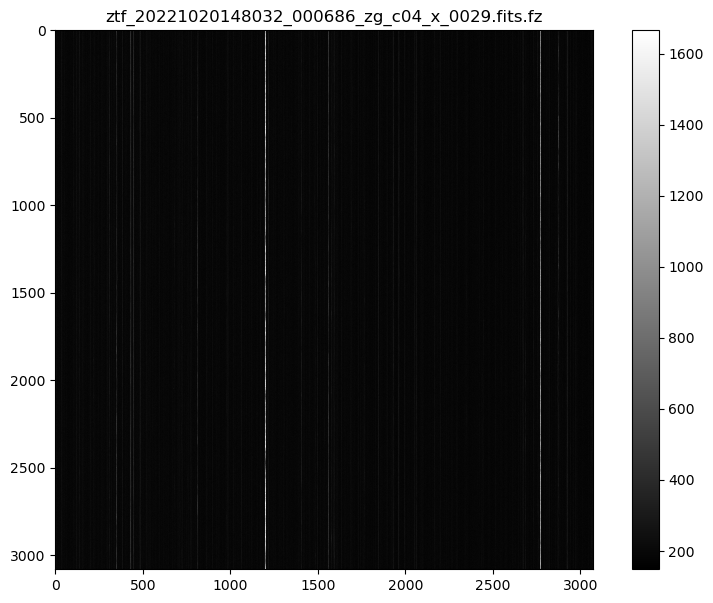

In [7]:
plt.imshow(file2_array)
plt.colorbar()
plt.title(fname2)

Text(0.5, 1.0, 'Difference')

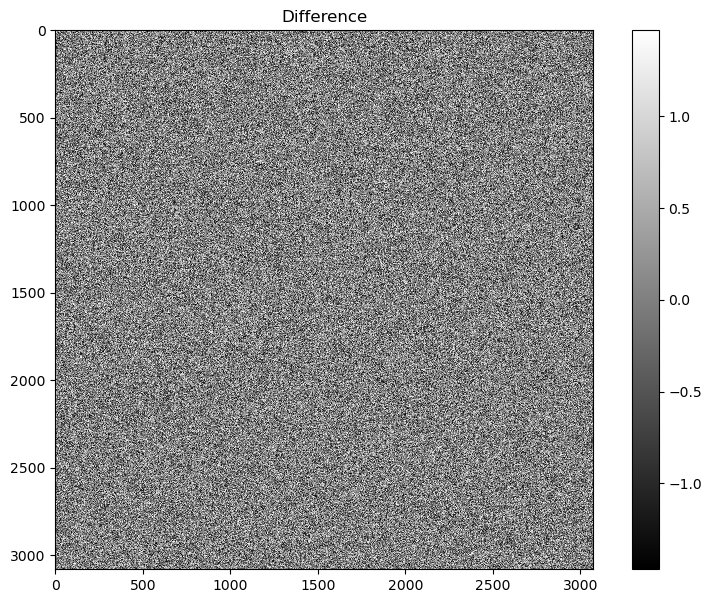

In [8]:

plt.imshow(file2_array- file1_array)
plt.colorbar()
plt.title("Difference")

In [15]:
def print_diff(fname, folder_path = '/lustre/lrspec/ZTF_data/2022/1020/'):
    '''
    we will take _0029 as input and find _0028
    '''
    path = folder_path + fname
    path2 = folder_path + fname[:-9]+'8'+fname[-8:]
    with fits.open(path) as hdul:
        with fits.open(path2) as hdul2:
            for quad in range(1,5):
                file1_array = hdul[quad].data
                file2_array = hdul2[quad].data
                print("max diff: ", np.max(np.abs(file1_array-file2_array)))
                print("flux maxes: ", np.max(file1_array), np.max(file2_array))
                plt.imshow(file2_array- file1_array)
                plt.colorbar()
                plt.title("Difference "+str(i))
                plt.show()
                      

In [22]:
def get_diff(fname, folder_path = '/lustre/lrspec/ZTF_data/2022/1020/'):
    '''
    we will take _0029 as input and find _0028
    '''
    diffs = []
    max1 = []
    max2 = []
    path = folder_path + fname
    path2 = folder_path + fname[:-9]+'8'+fname[-8:]
    with fits.open(path) as hdul:
        with fits.open(path2) as hdul2:
            for quad in range(1,5):
                file1_array = hdul[quad].data
                file2_array = hdul2[quad].data
                # print("max diff: ", np.max(np.abs(file1_array-file2_array)))
                # print("flux maxes: ", np.max(file1_array), np.max(file2_array))
                diffs.append(np.max(np.abs(file1_array-file2_array)))
                max1.append(np.max(file1_array))
                max2.append(np.max(file2_array))
    return diffs, max1, max2

max diff:  1.8911133
flux maxes:  3712.719 3713.2087


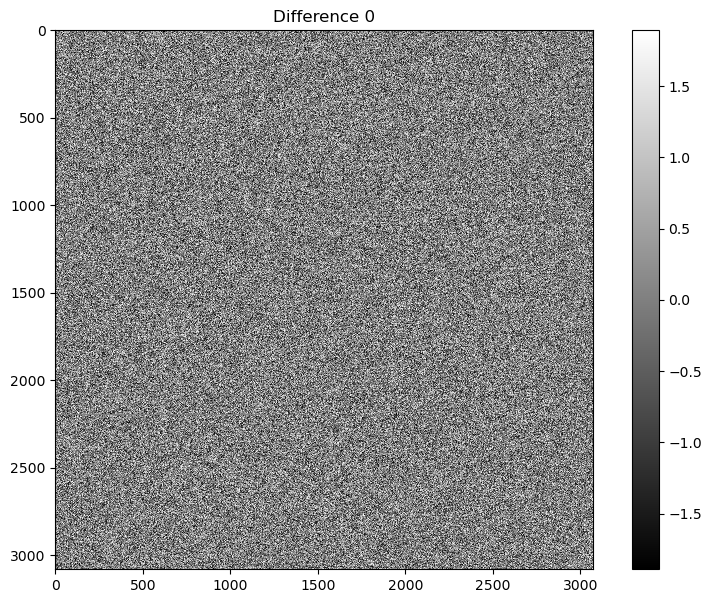

max diff:  2.1771698
flux maxes:  2053.4788 2053.17


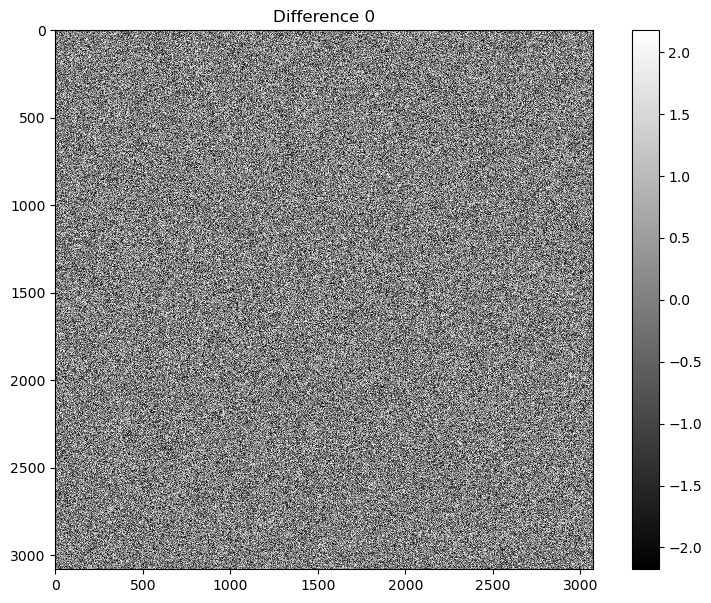

max diff:  2.2302704
flux maxes:  2384.562 2384.8647


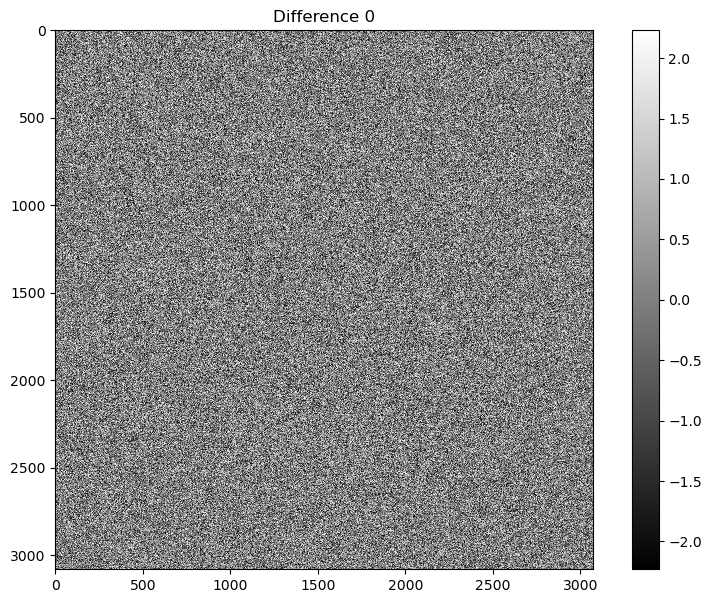

max diff:  1.94664
flux maxes:  5441.1533 5440.905


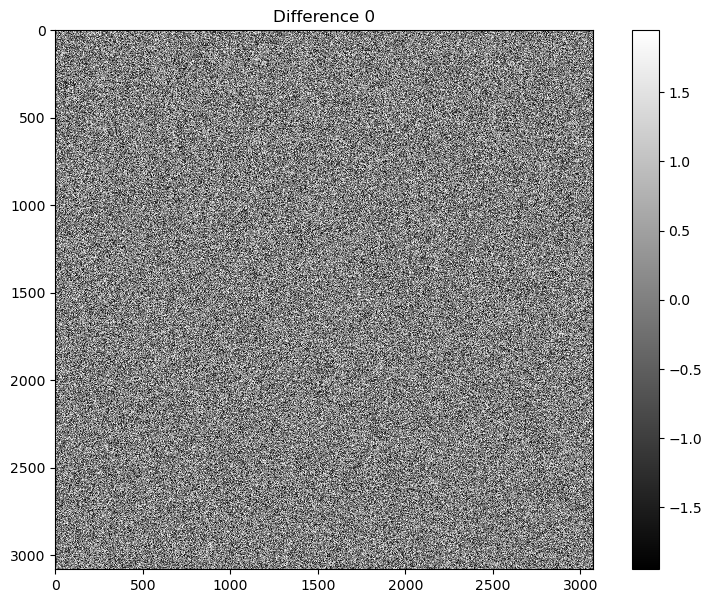

max diff:  1.729332
flux maxes:  4784.943 4784.8257


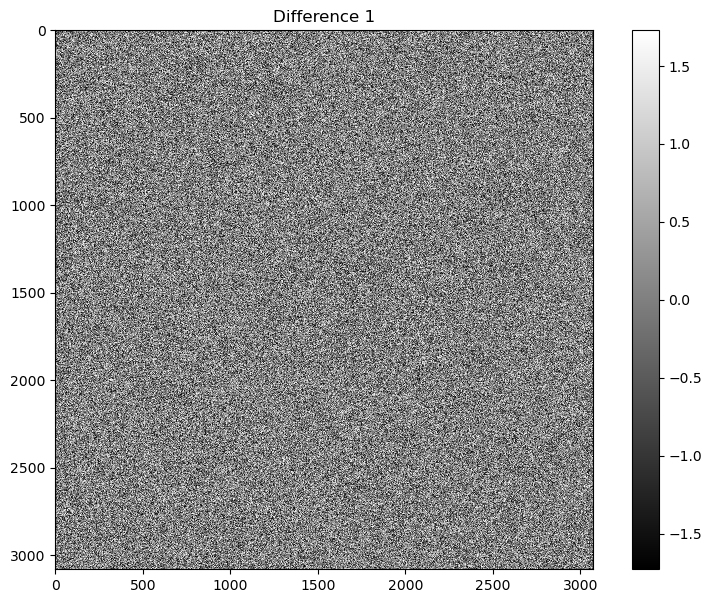

max diff:  1.6831512
flux maxes:  7032.913 7032.4243


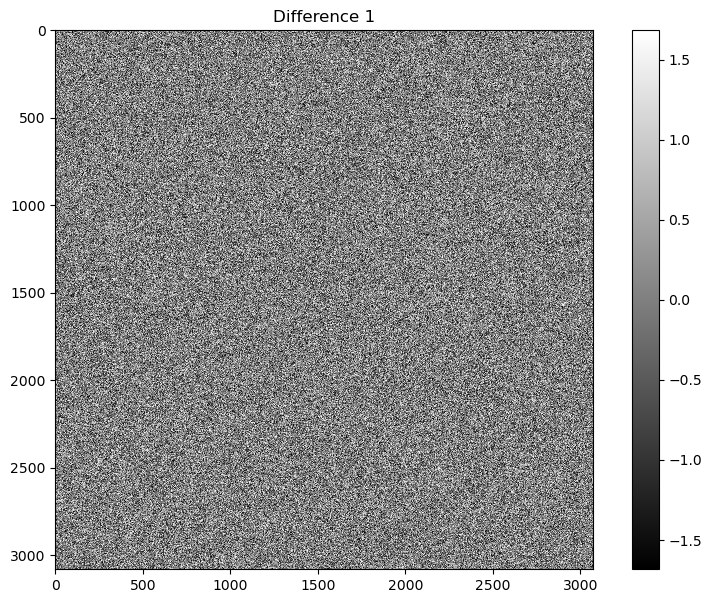

max diff:  1.6519318
flux maxes:  931.5227 931.94574


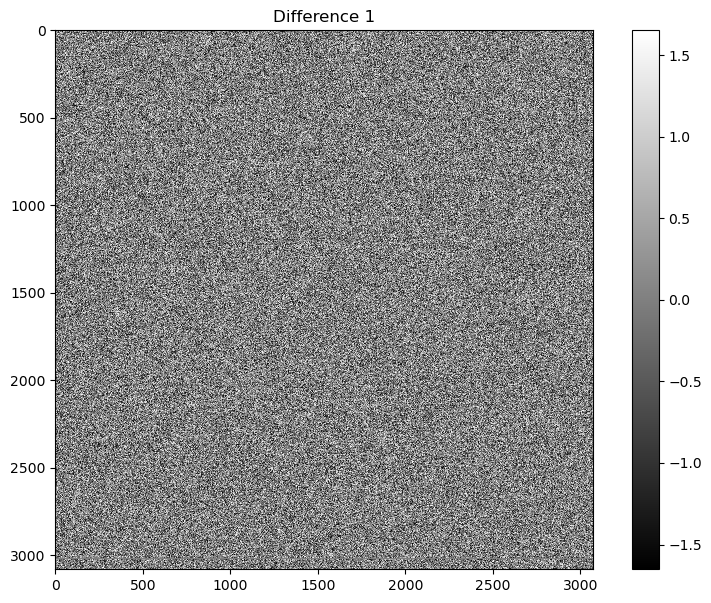

max diff:  1.5122986
flux maxes:  6448.018 6447.53


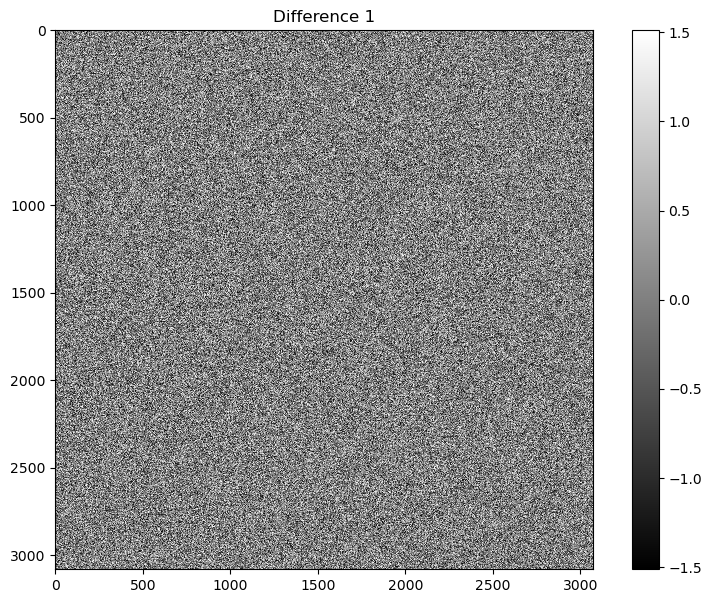

max diff:  1.5524445
flux maxes:  1679.6577 1679.9982


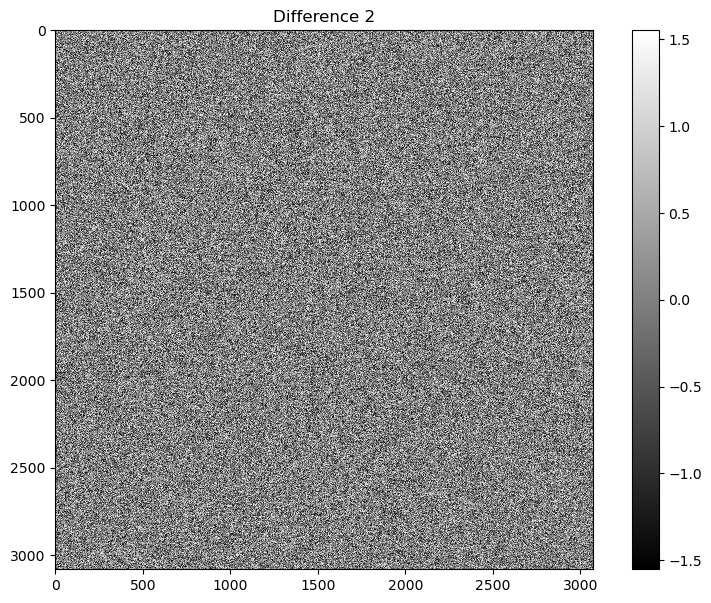

max diff:  1.5812988
flux maxes:  4007.559 4008.3513


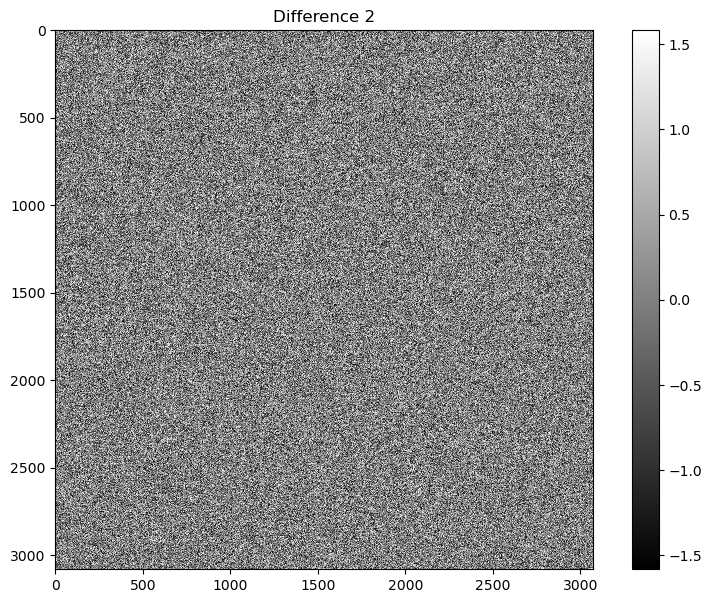

max diff:  1.6429443
flux maxes:  1921.6593 1921.7688


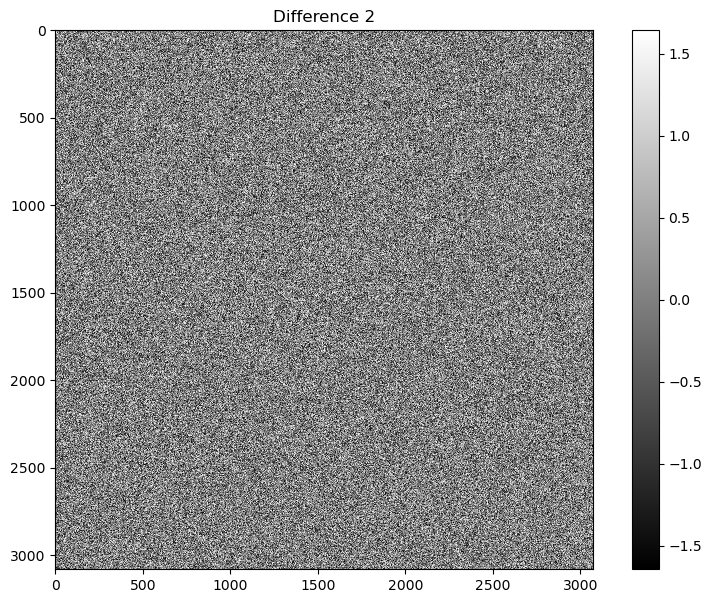

max diff:  1.7406464
flux maxes:  6167.153 6166.1963


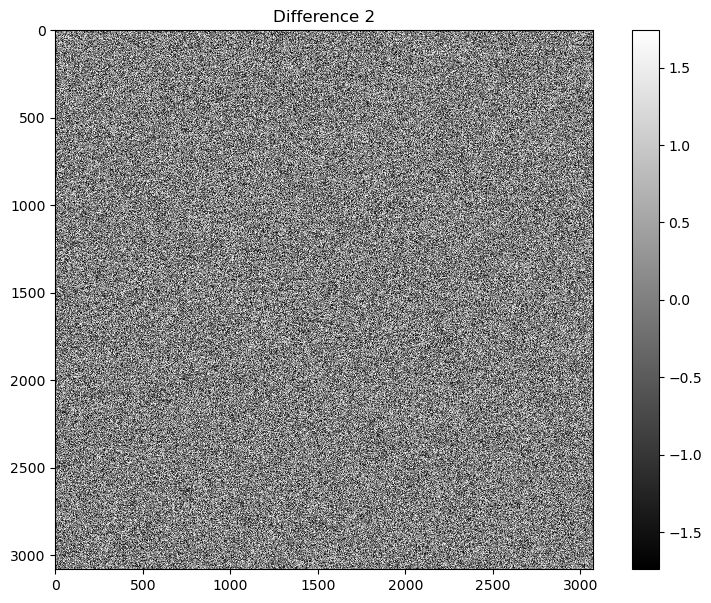

max diff:  1.1051636
flux maxes:  27602.99 27602.775


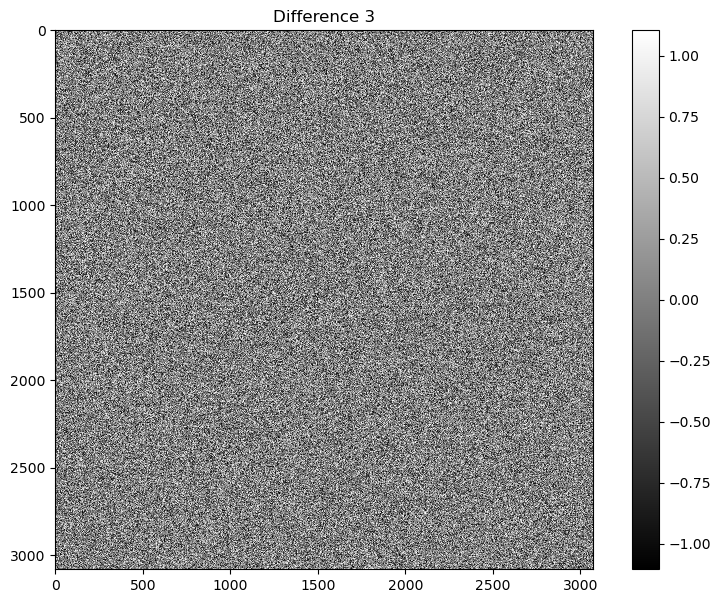

max diff:  1.0805359
flux maxes:  859.4098 859.19495


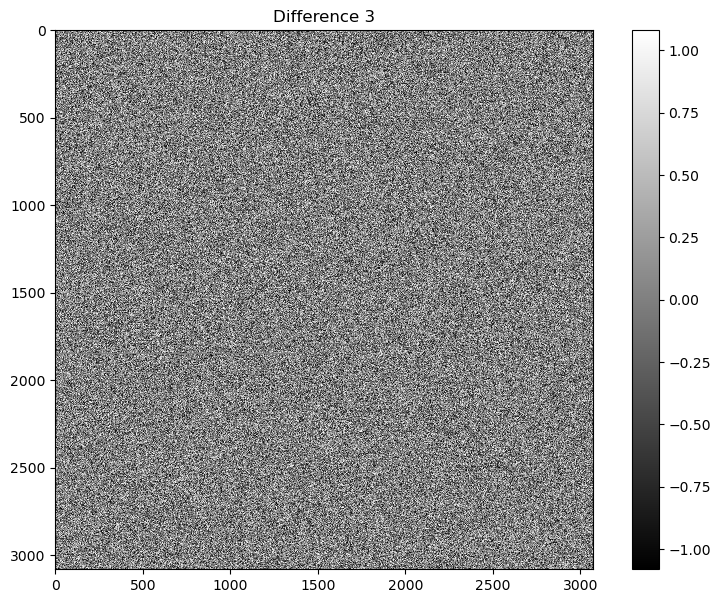

max diff:  1.0961456
flux maxes:  3307.7964 3308.2197


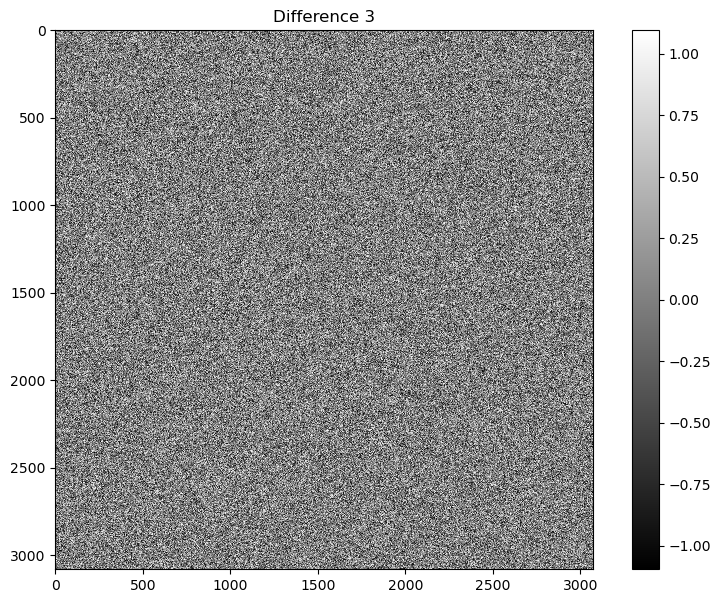

max diff:  1.1116333
flux maxes:  1025.3464 1025.3806


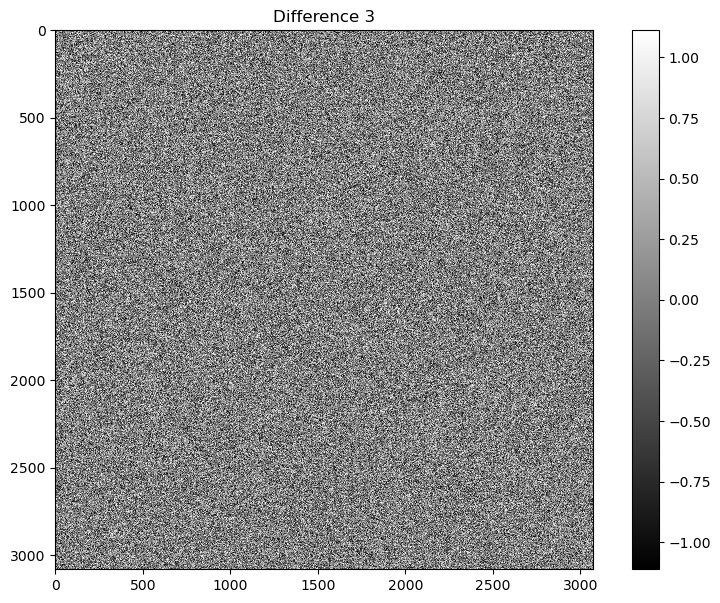

In [31]:
#okay so let's check some more
#maybe we make a function
folder_path = '/lustre/lrspec/ZTF_data/2022/1020/'

files = [f for f in os.listdir(folder_path) if f.endswith('0029.fits.fz')]  # Adjust this to your file format

for i, file in enumerate(files):
    print_diff(file)
    if i>2:
        break

max diff:  1.2776947
flux maxes:  6498.2266 6498.2207


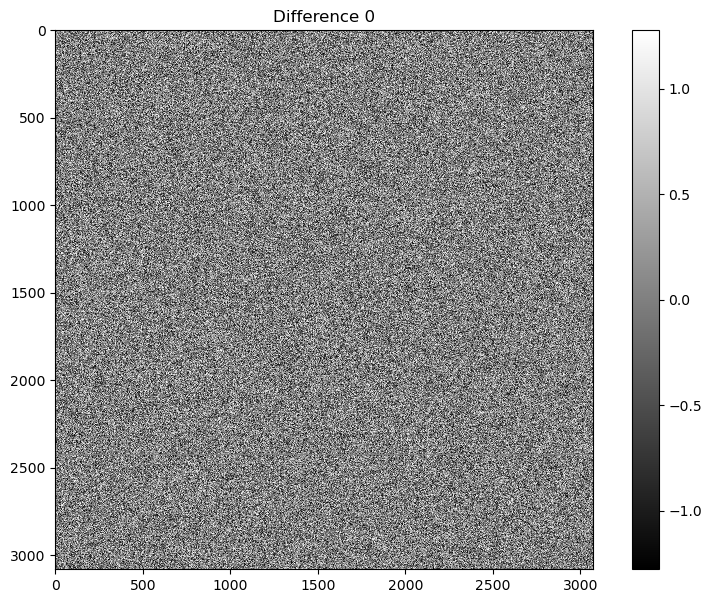

max diff:  1.2577362
flux maxes:  921.21045 921.43494


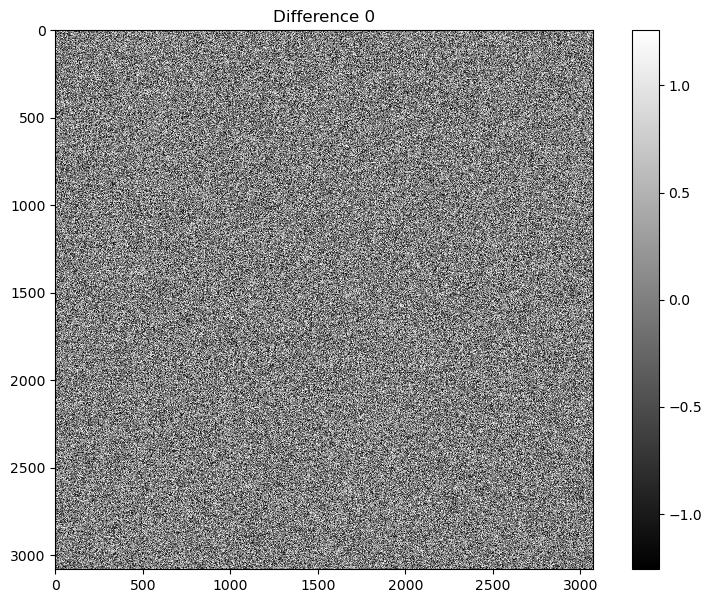

max diff:  1.2935333
flux maxes:  4108.8315 4108.2583


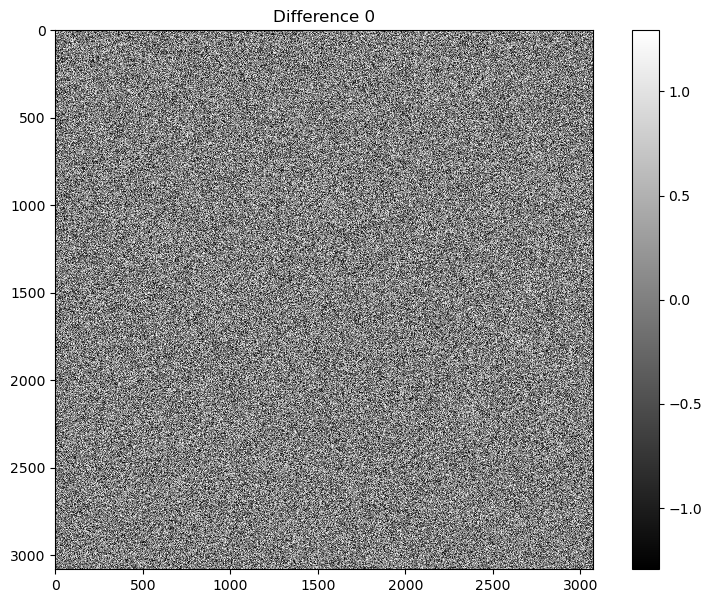

max diff:  1.2909546
flux maxes:  2744.4421 2744.1262


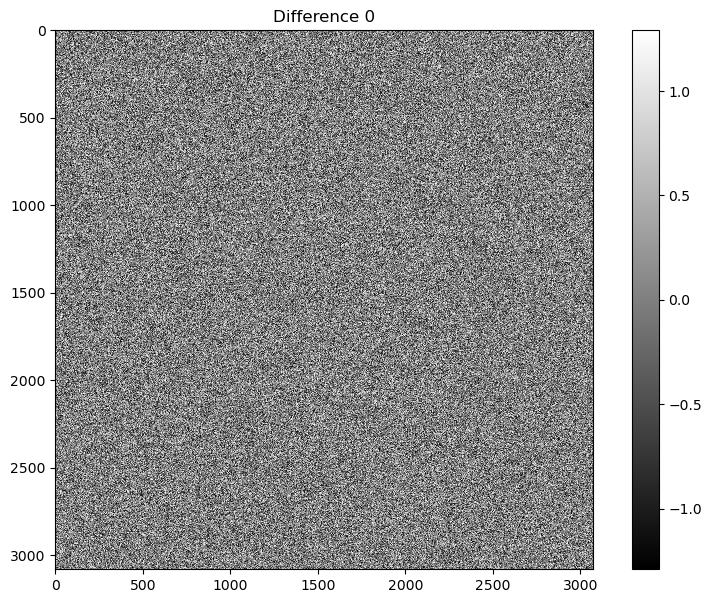

max diff:  0.9589081
flux maxes:  715.1483 715.1469


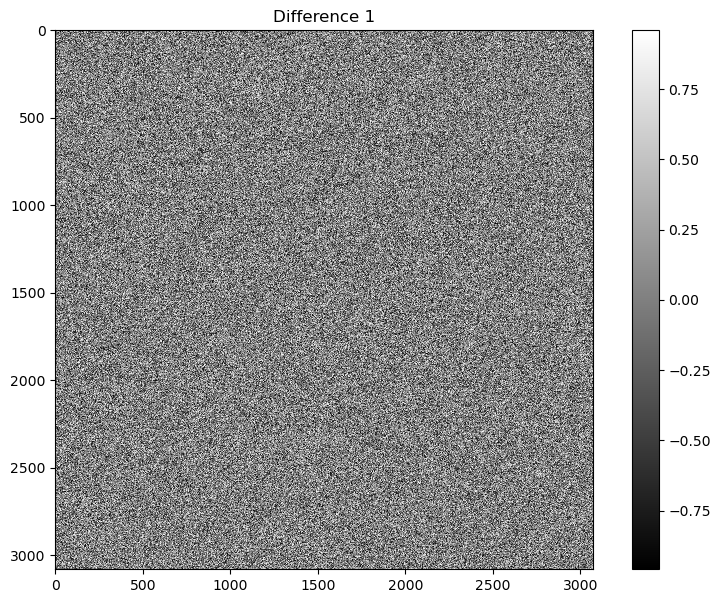

max diff:  0.9710846
flux maxes:  1392.5374 1393.3705


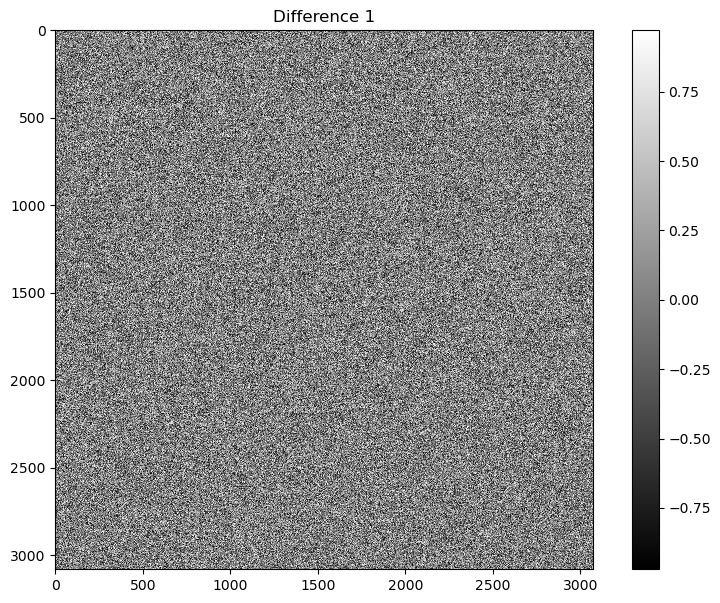

max diff:  0.98539734
flux maxes:  2609.5386 2609.7786


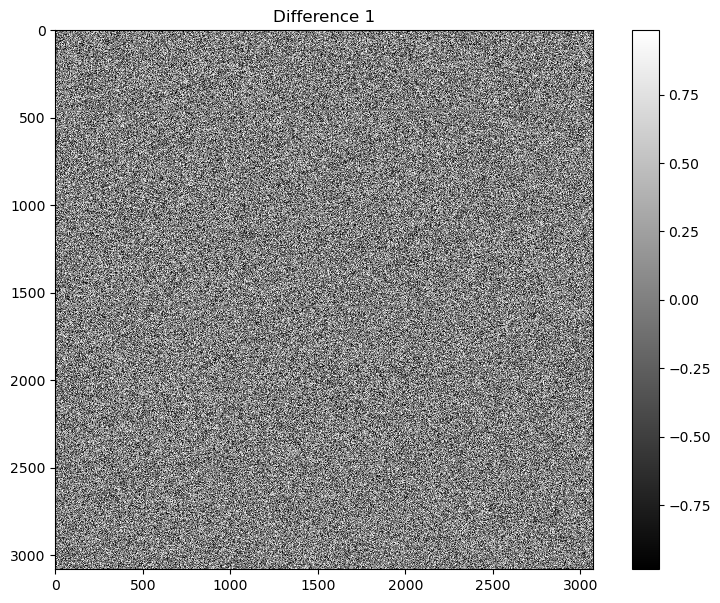

max diff:  0.98098755
flux maxes:  4930.8735 4931.3945


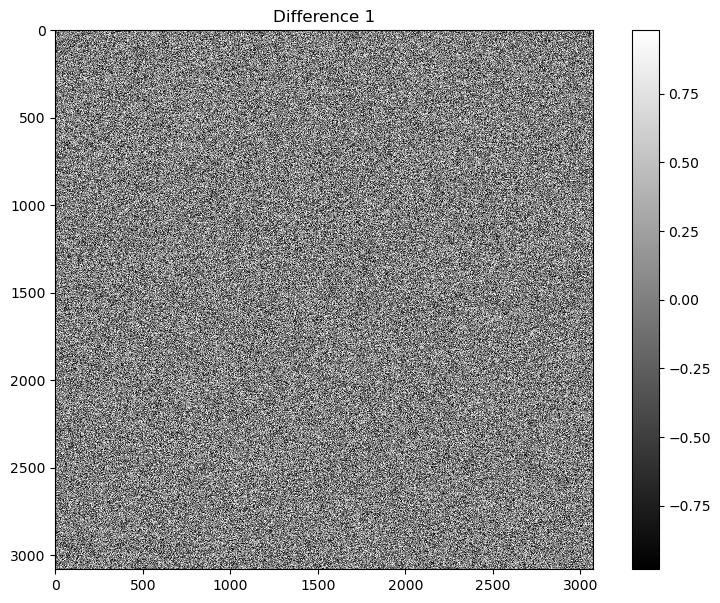

max diff:  1.1957245
flux maxes:  532.8564 532.48016


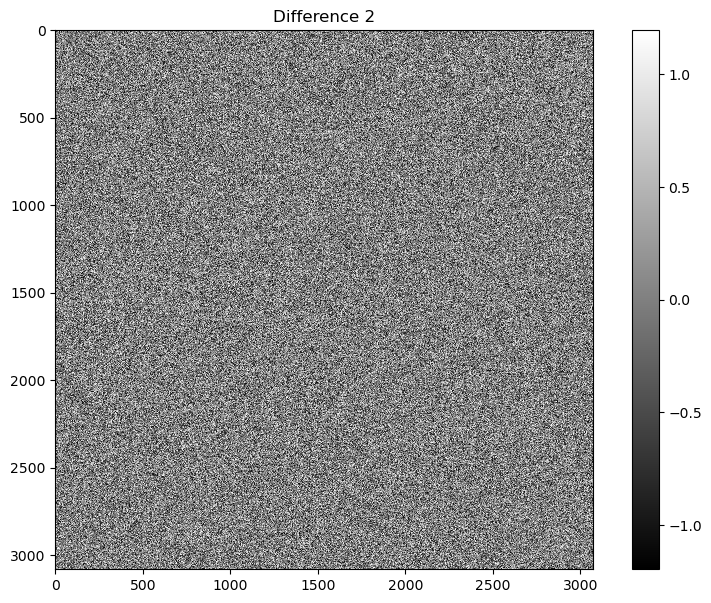

max diff:  1.2176208
flux maxes:  2693.919 2694.3538


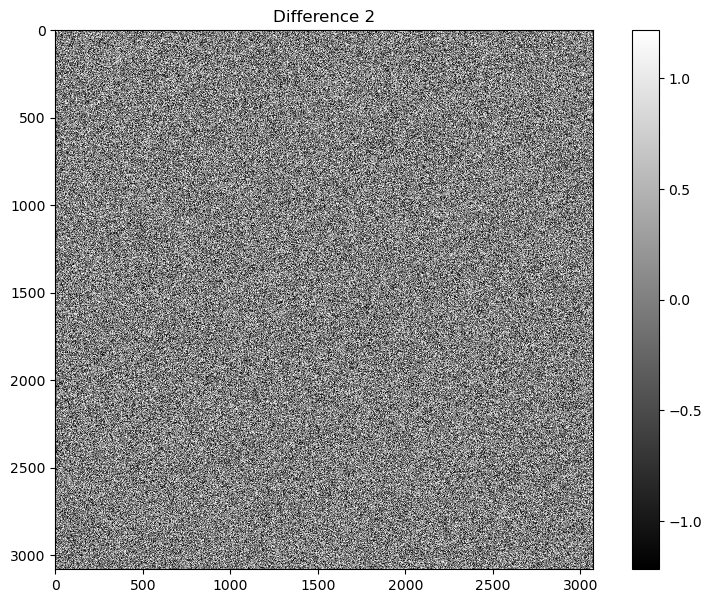

max diff:  1.2359314
flux maxes:  2692.2375 2692.005


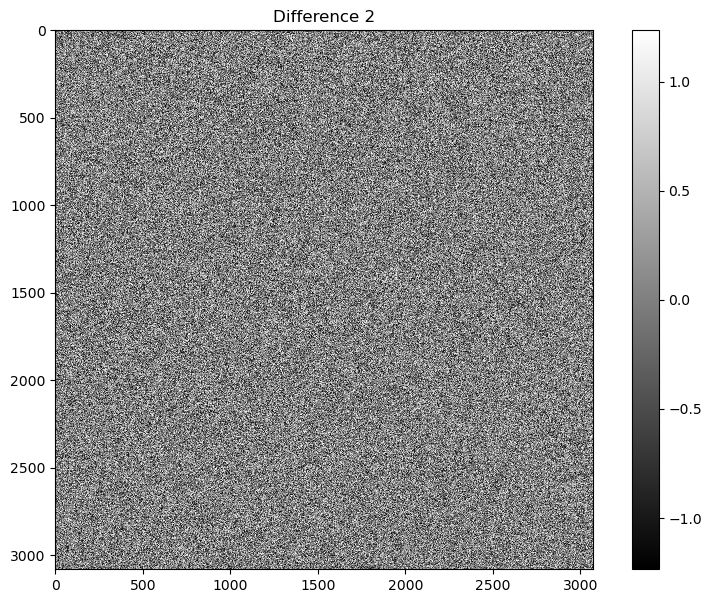

max diff:  1.2404175
flux maxes:  2810.557 2810.6763


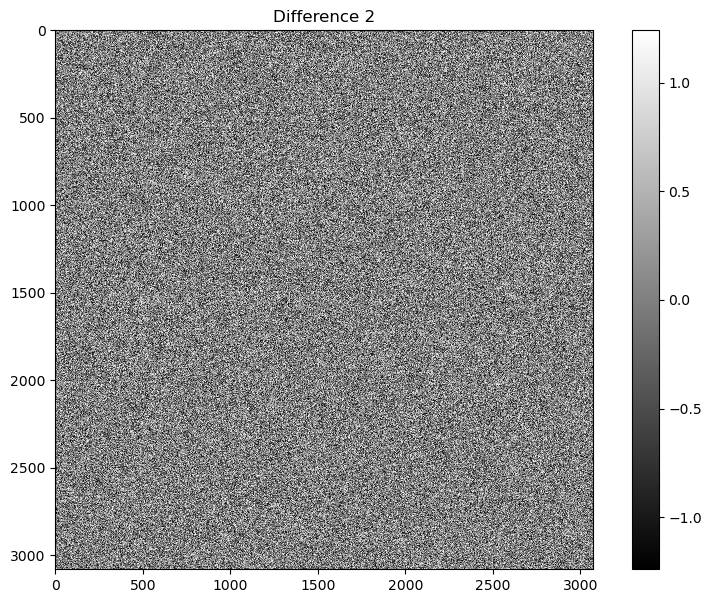

max diff:  1.466156
flux maxes:  980.93933 981.7555


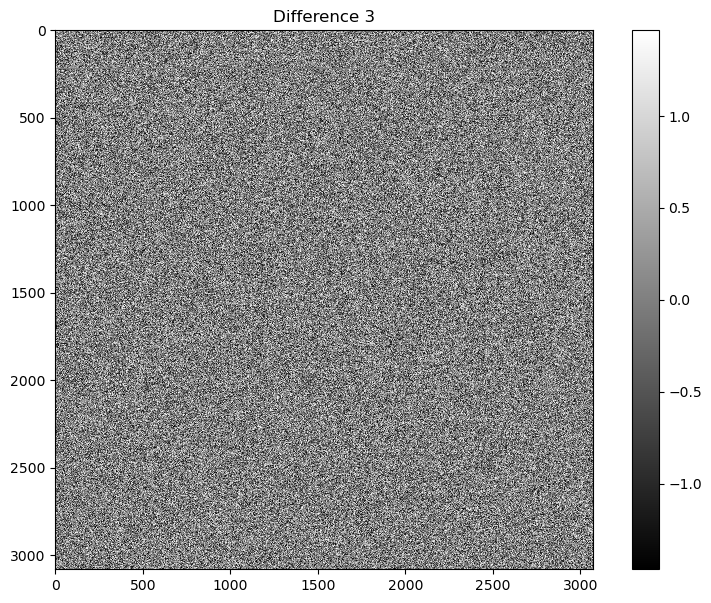

max diff:  1.3351746
flux maxes:  2024.6251 2024.561


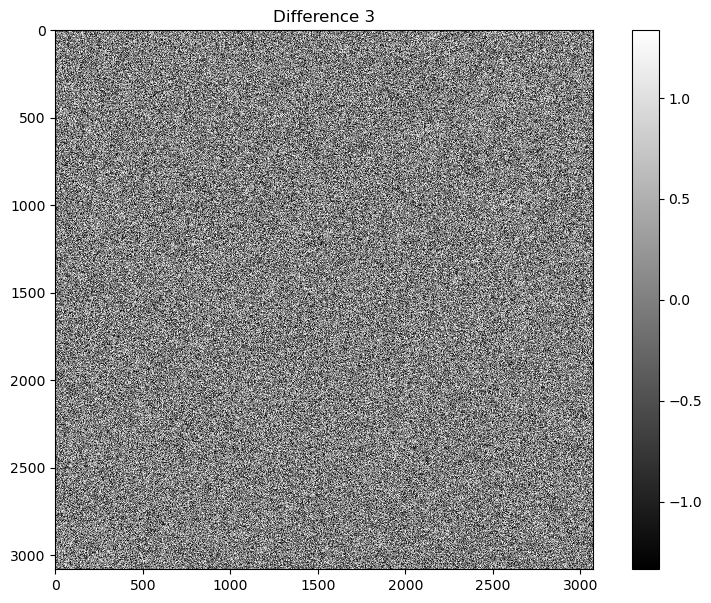

max diff:  1.2645416
flux maxes:  955.4703 956.3397


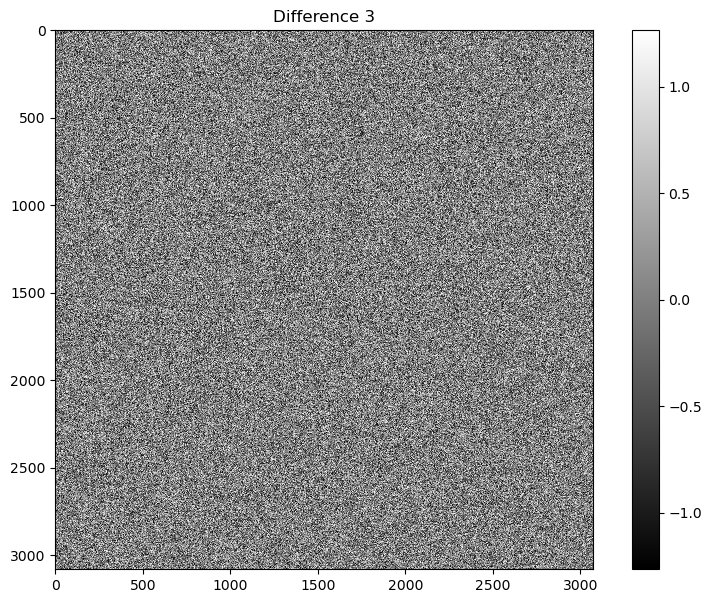

max diff:  1.4130249
flux maxes:  4474.0635 4473.3843


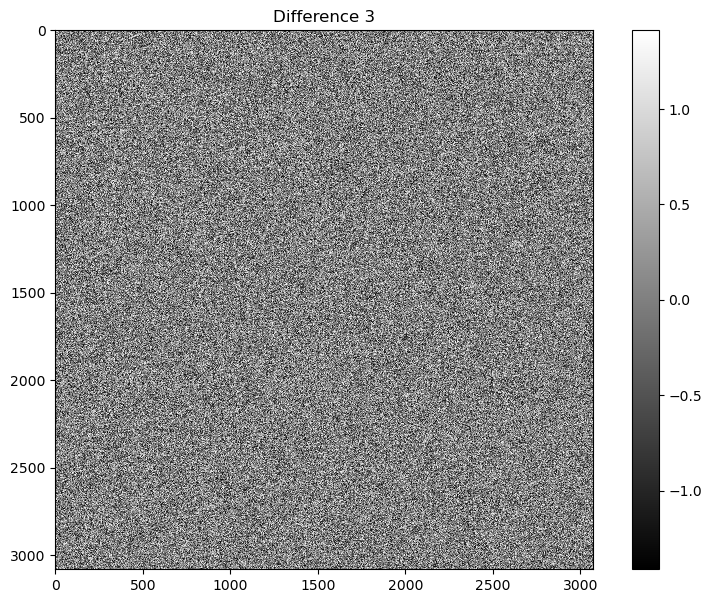

In [32]:
folder_path = '/lustre/lrspec/ZTF_data/2022/1026/'

files = [f for f in os.listdir(folder_path) if f.endswith('0029.fits.fz')]  # Adjust this to your file format

for i, file in enumerate(files):
    print_diff(file, folder_path=folder_path)
    if i>2:
        break

In [30]:
folder_path = '/lustre/lrspec/ZTF_data/2022/1017/'

files = [f for f in os.listdir(folder_path) if f.endswith('0029.fits.fz')]  # Adjust this to your file format
#commenting this out because the file was too big...
#but it showed the same thing

# for i, file in enumerate(files):
#     print_diff(file, folder_path=folder_path)
#     if i>10:
#         break

In [23]:
folder_path = '/lustre/lrspec/ZTF_data/2022/1017/'

files = [f for f in os.listdir(folder_path) if f.endswith('0029.fits.fz')]  # Adjust this to your file format
diffss = []
max1s =  []
max2s = []
for i, file in enumerate(files):
    diffs, max1, max2 = get_diff(file, folder_path=folder_path)
    diffss.append(np.array(diffs))
    max1s.append(np.array(max1))
    max2s.append(np.array(max2))

KeyboardInterrupt: 

In [26]:
np.max(np.array(diffss).flatten())

2.7682877

In [27]:
folder_path = '/lustre/lrspec/ZTF_data/2022/1020/'

files = [f for f in os.listdir(folder_path) if f.endswith('0029.fits.fz')]  # Adjust this to your file format
diffss = []
max1s =  []
max2s = []
for i, file in enumerate(files):
    diffs, max1, max2 = get_diff(file, folder_path=folder_path)
    diffss.append(np.array(diffs))
    max1s.append(np.array(max1))
    max2s.append(np.array(max2))

In [28]:
np.max(np.array(diffss).flatten())

2.7807312